# 07 — Paderborn: A Healthy-Baseline Anomaly Channel (and What It Costs)

Notebook 06 ended with a concrete proposal: pair the fault-frequency
classifier with a **healthy-baseline anomaly detector**, because KA22 is
*detectable but not attributable* — it carries +14.3 dB at 144.5 Hz
(≈ 5.75 × shaft rate) while reading +1.6 dB at BPFO. A detector that asks
"does this spectrum deviate from healthy?" instead of "is there energy at
BPFO?" should catch it, and possibly KA30 too.

This notebook builds that channel and measures it honestly. Three design
commitments, all forced by earlier findings:

1. **Order-normalized representation.** Instead of six hand-picked fault
   frequencies, describe the whole envelope spectrum as 59 half-order bands
   from 1.0 to 30.0 × shaft rate. Speed-normalized by construction, and wide
   enough to contain KA22's off-frequency line — a fault-frequency feature
   set can *never* see it (notebook 06).
2. **The healthy baseline is fitted on healthy bearings only, and evaluated
   leave-one-*healthy-bearing*-out.** Notebook 05 banned recording-level CV;
   the same rule applies here. The number that matters is the false-alarm
   rate on a healthy bearing the baseline has **never seen** — the exact
   situation of a newly commissioned motor.
3. **The metric is the safety pair, not accuracy:** missed-fault rate on
   real damage vs false-alarm rate on unseen healthy units. Notebooks 04–06
   reported accuracy on faulty bearings and never once measured what the
   pipeline does to a healthy bearing it has not met.

That third commitment turns out to matter more than the anomaly channel
itself.

In [1]:
import functools
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt, hilbert, get_window
from sklearn.covariance import LedoitWolf
from sklearn.ensemble import IsolationForest, RandomForestClassifier

DATA_DIR = pathlib.Path("../data/raw/paderborn")
CONDITION = "N15_M07_F10"
FS_HIGH_HZ = 64_000
N_BALLS, BALL_D_MM, PITCH_D_MM = 8, 6.75, 29.05
RATIO = BALL_D_MM / PITCH_D_MM
ORD_BPFO = N_BALLS / 2 * (1 - RATIO)   # 3.071 x shaft rate
ORD_BPFI = N_BALLS / 2 * (1 + RATIO)   # 4.929 x shaft rate

BEARINGS = (
    [(f"K00{i}", "Healthy", "healthy") for i in range(1, 7)]
    + [(c, "OR", "artificial") for c in ("KA01", "KA03", "KA05", "KA07")]
    + [(c, "IR", "artificial") for c in ("KI01", "KI03", "KI05", "KI07")]
    + [(c, "OR", "real") for c in ("KA04", "KA15", "KA16", "KA22", "KA30")]
    + [(c, "IR", "real") for c in ("KI04", "KI14", "KI16", "KI17", "KI18", "KI21")]
)

N_KEEP = 245_760          # 15 windows x 16384 samples
WIN, N_WIN = 16_384, 15
HANN = get_window("hann", WIN)
WIN_FREQS = np.fft.rfftfreq(WIN, 1 / FS_HIGH_HZ)
FLOOR_MASK = (WIN_FREQS > 10) & (WIN_FREQS < 400)
SOS_ENV = butter(4, (1000, 20000), btype="bandpass", fs=FS_HIGH_HZ, output="sos")

# 59 half-order bands, centres 1.0 ... 30.0 x fr. Centres are chosen so that
# fr (1.0), BPFO (3.07), BPFI (4.93), 2xBPFO (6.14), 3xBPFO (9.21) and
# 2xBPFI (9.86) each fall *inside* a band rather than on a boundary.
ORDER_CENTERS = np.round(np.arange(1.0, 30.0 + 1e-9, 0.5), 2)
HALF_ORDER = 0.25
BAND_COLS = [f"O{c:g}".replace(".", "p") for c in ORDER_CENTERS]

FLAT_MASK = (WIN_FREQS >= 10) & (WIN_FREQS <= 1000)
HF_MASK = (WIN_FREQS >= 1000) & (WIN_FREQS <= 20000)
TOT_MASK = (WIN_FREQS >= 10) & (WIN_FREQS <= 30000)


def load_channels(mat_path):
    mat_path = pathlib.Path(mat_path)
    struct = loadmat(mat_path)[mat_path.stem]
    channels = struct["Y"][0, 0][0]
    return {str(ch["Name"][0]): ch["Data"].squeeze() for ch in channels}


def windowed(sig):
    w = sig[: N_WIN * WIN].reshape(N_WIN, WIN).astype(np.float64)
    return w - w.mean(axis=1, keepdims=True)


def power_spectrum(w):
    return np.abs(np.fft.rfft(w * HANN, axis=1)) ** 2


def band_peak_db(spec, target_hz, floor, halfwidth=4.0):
    m = (WIN_FREQS >= target_hz - halfwidth) & (WIN_FREQS <= target_hz + halfwidth)
    return 10 * np.log10(spec[:, m].max(axis=1) / floor)


def run_features(code, run):
    """15 windows x (59 order bands + 3 shape features + the 3 notebook-05 fundamentals)."""
    chans = load_channels(DATA_DIR / code / f"{CONDITION}_{code}_{run}.mat")
    vib = chans["vibration_1"][:N_KEEP].astype(np.float64)
    fr = float(chans["speed"].mean()) / 60.0

    bandpassed = sosfiltfilt(SOS_ENV, vib)
    env = np.abs(hilbert(bandpassed))
    espec = power_spectrum(windowed(env - env.mean()))
    efloor = np.median(espec[:, FLOOR_MASK], axis=1)
    edb = 10 * np.log10(espec / efloor[:, None])

    bands = np.empty((N_WIN, len(ORDER_CENTERS)))
    for j, centre in enumerate(ORDER_CENTERS):
        m = (WIN_FREQS >= (centre - HALF_ORDER) * fr) & (WIN_FREQS < (centre + HALF_ORDER) * fr)
        bands[:, j] = edb[:, m].max(axis=1)

    # Level-invariant shape features - the distributed/indentation-damage
    # indicators notebook 06 asked for (broadband floor shift, peakiness).
    s = espec[:, FLAT_MASK]
    flatness_db = 10 * np.log10(np.exp(np.log(s).mean(axis=1)) / s.mean(axis=1))
    bw = windowed(bandpassed)
    kurt = (bw ** 4).mean(axis=1) / (bw ** 2).mean(axis=1) ** 2
    vspec = power_spectrum(windowed(vib))
    hf_ratio = vspec[:, HF_MASK].sum(axis=1) / vspec[:, TOT_MASK].sum(axis=1)

    out = pd.DataFrame(bands, columns=BAND_COLS)
    out["Env_BPFO_dB"] = band_peak_db(espec, ORD_BPFO * fr, efloor)
    out["Env_BPFI_dB"] = band_peak_db(espec, ORD_BPFI * fr, efloor)
    out["Env_fr_dB"] = band_peak_db(espec, fr, efloor)
    out["Env_Flatness_dB"] = flatness_db
    out["Vib_BP_Kurtosis"] = kurt
    out["Vib_HF_Ratio"] = hf_ratio
    out["fr_Hz"] = fr
    out["Window"] = np.arange(N_WIN)
    return out


# chart tokens - identical to notebooks 05/06
C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
SEQ = LinearSegmentedColormap.from_list("seq", [SURFACE, "#a8c9ee", C_BLUE, "#123a68"])
CLASS_COLOR = {"Healthy": MUTED, "OR": C_BLUE, "IR": C_ORANGE}
print(f"{len(ORDER_CENTERS)} order bands, {ORDER_CENTERS[0]}-{ORDER_CENTERS[-1]} x fr "
      f"(BPFO = {ORD_BPFO:.3f}, BPFI = {ORD_BPFI:.3f})")

59 order bands, 1.0-30.0 x fr (BPFO = 3.071, BPFI = 4.929)


## Feature extraction — the envelope spectrum as a shape, not six numbers

Same signal chain as notebooks 03/05 (1–20 kHz band-pass → Hilbert envelope →
15 Hann-windowed periodograms → dB over the per-window 10–400 Hz median
floor). The only change is what gets read off the spectrum: **every** half-order
band from 1 to 30 × shaft rate, rather than the six fault-frequency peaks.

The three notebook-05 fundamentals are recomputed here as well, so the
classifier channel and the anomaly channel are row-aligned by construction —
and the values can be checked against the existing feature table.

In [2]:
tables = []
for code, condition, domain in BEARINGS:
    for run in range(1, 21):
        f = run_features(code, run)
        f["Code"], f["Condition"], f["Domain"], f["Run"] = code, condition, domain, run
        tables.append(f)
ds = pd.concat(tables, ignore_index=True)

OUT = pathlib.Path("../data/processed")
csv_path = OUT / f"pu_{CONDITION}_envelope_orderbands.csv"
ds.to_csv(csv_path, index=False)
print(f"saved {ds.shape[0]} rows x {ds.shape[1]} cols -> {csv_path}")

# The fundamentals must reproduce notebook 05's table exactly - same recipe,
# same row order. If this assert ever fires, the two channels are misaligned.
FUND = ["Env_BPFO_dB", "Env_BPFI_dB", "Env_fr_dB"]
ref = pd.read_csv(OUT / f"pu_{CONDITION}_spectral_features_scaled.csv")
assert np.allclose(ds[FUND].to_numpy(), ref[FUND].to_numpy())
print("fundamentals match notebook 05's feature table exactly (row-aligned)")

BANDS = BAND_COLS
SHAPE = ["Env_Flatness_dB", "Vib_BP_Kurtosis", "Vib_HF_Ratio"]
HEALTHY = [c for c, cond, _ in BEARINGS if cond == "Healthy"]
DAMAGED = [c for c, cond, _ in BEARINGS if cond != "Healthy"]
REAL = [c for c, _, d in BEARINGS if d == "real"]
LABEL = ds.drop_duplicates("Code").set_index("Code")[["Condition", "Domain"]]
RF_KW = dict(n_estimators=300, random_state=0, n_jobs=-1)

saved 7500 rows x 71 cols -> ..\data\processed\pu_N15_M07_F10_envelope_orderbands.csv
fundamentals match notebook 05's feature table exactly (row-aligned)


## Before detecting anything: what does "healthy" look like?

An anomaly detector is only as good as its reference distribution. Paderborn
gives six healthy bearings of the same type (6203) on the same rig, differing
only in run-in history (Lessmeier et al. 2016, **Table 7**: K001 > 50 h,
K002 19 h, K003 1 h, K004 5 h, K005 10 h, K006 16 h). If "healthy" is a
tight cluster, a pooled baseline is trustworthy. If it is not, every
false-alarm number below is explained before it is measured.

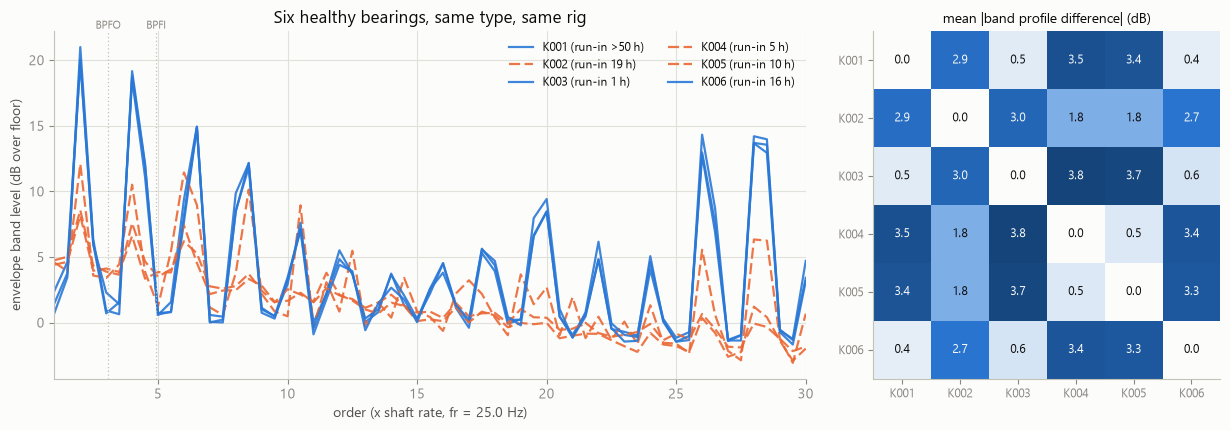

      order 1  order 2  order 3  order 4  order 5  order 6.5  order 20
Code                                                                  
K001     1.47    20.04     0.70    18.79     0.73      14.87      8.48
K002     4.58    12.09     3.41    10.50     1.25       8.97      2.69
K003     0.73    20.99     0.92    19.16     0.58      14.94      9.42
K004     4.75     8.57     3.88     7.58     3.49       5.27     -0.02
K005     4.41     8.15     4.12     6.60     3.85       4.55      0.37
K006     2.42    19.92     2.29    18.56     0.61      14.87      8.45


In [3]:
prof = ds[ds["Domain"] == "healthy"].groupby("Code")[BANDS].median()
dist = pd.DataFrame(
    [[np.abs(prof.loc[a] - prof.loc[b]).mean() for b in HEALTHY] for a in HEALTHY],
    index=HEALTHY, columns=HEALTHY)

fig, (ax, axd) = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw=dict(width_ratios=[2.05, 1]))
RUN_IN = {"K001": ">50 h", "K002": "19 h", "K003": "1 h",
          "K004": "5 h", "K005": "10 h", "K006": "16 h"}
GROUP_A = ["K001", "K003", "K006"]
for c in HEALTHY:
    in_a = c in GROUP_A
    ax.plot(ORDER_CENTERS, prof.loc[c], lw=1.6 if in_a else 1.6, alpha=0.9,
            color=C_BLUE if in_a else C_ORANGE, ls="-" if in_a else (0, (5, 2)),
            label=f"{c} (run-in {RUN_IN[c]})")
for o, name in ((ORD_BPFO, "BPFO"), (ORD_BPFI, "BPFI")):
    ax.axvline(o, color=BASE, lw=0.9, ls=(0, (1, 2)))
    ax.text(o, 22.4, name, color=MUTED, fontsize=8, ha="center")
ax.set_xlabel("order (x shaft rate, fr = 25.0 Hz)")
ax.set_ylabel("envelope band level (dB over floor)")
ax.set_title("Six healthy bearings, same type, same rig")
ax.legend(fontsize=8.5, ncol=2, loc="upper right")
ax.set_xlim(1, 30)

im = axd.imshow(dist.to_numpy(), cmap=SEQ, vmin=0, vmax=4)
axd.set_xticks(range(6), HEALTHY, fontsize=8.5)
axd.set_yticks(range(6), HEALTHY, fontsize=8.5)
for i in range(6):
    for j in range(6):
        v = dist.iat[i, j]
        axd.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8.5,
                 color=SURFACE if v > 2.2 else INK)
axd.grid(visible=False)
axd.set_title("mean |band profile difference| (dB)", fontsize=10)
plt.tight_layout()
plt.show()

print(prof[[c for c in BANDS if c in ("O1", "O2", "O3", "O4", "O5", "O6p5", "O20")]]
      .rename(columns=lambda c: c.replace("p", ".").replace("O", "order "))
      .round(2).to_string())

## Reading the healthy baseline: two rigs wearing one label

- **The six healthy bearings are not one population — they are two.**
  K001/K003/K006 sit within 0.36–0.61 dB of each other, K004/K005 within
  0.51 dB, and the two groups are **2.7–3.8 dB apart** on average across all
  59 bands; K002 sits between them. That is a larger separation than several
  *damaged* bearings show against healthy (see the severity table below).
- **The split does not follow run-in time.** K001 (> 50 h) and K003 (1 h)
  are the two most similar bearings in the set. Whatever separates the
  groups, it is not accumulated wear — the one variable Table 7 documents.
- **What actually separates them is the rig, not the bearing.** The
  ≈ 52.7 Hz harmonic family notebook 03 flagged as envelope contamination
  (orders ≈ 2.1, 4.2, 6.3) is a *20 dB* feature in K001/K003/K006 and only
  8–12 dB in K004/K005. The "healthy signature" is substantially an
  **installation signature** — mounting, seating, assembly — and it is the
  thing a baseline learns first.
- Consequence for the framework: a digital twin that simulates a healthy
  bearing simulates the wrong thing. The deployable reference is a healthy
  baseline **of that unit, in that installation** — notebook 05's per-unit
  calibration finding, arriving again from an entirely different direction.

## How expensive is that spread? A cross-unit false-alarm matrix

Direct test of the deployment question: fit the baseline on **one** healthy
bearing, set the alarm threshold at its own 99th percentile (1 % in-sample
false alarms), then apply it to each of the other five healthy bearings and
to the 19 damaged ones. Row = the bearing the baseline came from.

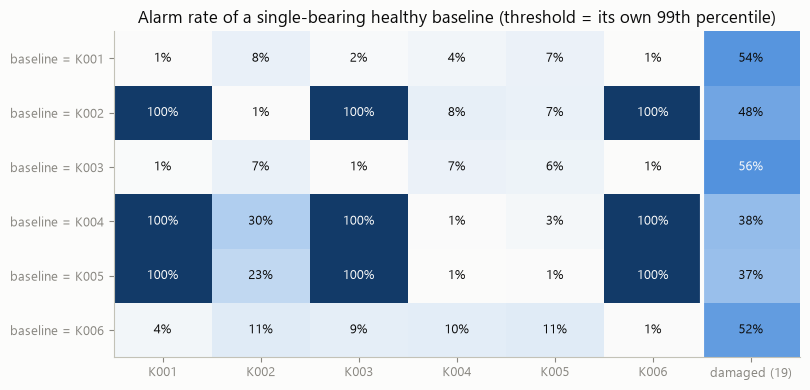

K004 baseline vs K001: dominant band = order 28.0 (700 Hz), median z = 4.6


In [4]:
class Exceedance:
    """Robust per-band z over the healthy baseline, max-pooled across bands."""

    def fit(self, X):
        self.med = np.median(X, axis=0)
        self.mad = np.maximum(1.4826 * np.median(np.abs(X - self.med), axis=0), 0.1)
        return self

    def z(self, X):
        return (X - self.med) / self.mad

    def score(self, X):
        return self.z(X).max(axis=1)


X_of = {c: ds.loc[ds["Code"] == c, BANDS].to_numpy() for c in HEALTHY + DAMAGED}
cross = pd.DataFrame(index=HEALTHY, columns=HEALTHY + ["damaged (19)"], dtype=float)
for a in HEALTHY:
    m = Exceedance().fit(X_of[a])
    thr = np.quantile(m.score(X_of[a]), 0.99)
    for b in HEALTHY:
        cross.loc[a, b] = (m.score(X_of[b]) > thr).mean()
    cross.loc[a, "damaged (19)"] = np.mean([(m.score(X_of[c]) > thr).mean() for c in DAMAGED])

fig, ax = plt.subplots(figsize=(8.2, 4.0))
ax.imshow(cross.to_numpy(), cmap=SEQ, vmin=0, vmax=1, aspect="auto")
for i in range(cross.shape[0]):
    for j in range(cross.shape[1]):
        v = cross.iat[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9,
                color=SURFACE if v > 0.55 else INK)
ax.set_xticks(range(cross.shape[1]), list(cross.columns), fontsize=9)
ax.set_yticks(range(6), [f"baseline = {c}" for c in HEALTHY], fontsize=9)
ax.axvline(5.5, color=SURFACE, lw=3)
ax.grid(visible=False)
ax.set_title("Alarm rate of a single-bearing healthy baseline (threshold = its own 99th percentile)")
plt.tight_layout()
plt.show()

# which band drives the cross-unit alarms?
m4 = Exceedance().fit(X_of["K004"])
worst = np.bincount(m4.z(X_of["K001"]).argmax(axis=1), minlength=len(BANDS)).argmax()
print(f"K004 baseline vs K001: dominant band = order {ORDER_CENTERS[worst]:.1f} "
      f"({ORDER_CENTERS[worst] * 25:.0f} Hz), median z = {np.median(m4.z(X_of['K001'])[:, worst]):.1f}")

## Reading the cross-unit matrix

- **A healthy baseline can be 100 % wrong on another healthy bearing of the
  same type.** Calibrated to 1 % on itself, the K004 baseline flags
  **every single window** of K001, K003 and K006 — and the K002 and K005
  baselines do the same. Six identical part numbers on one rig, and half the
  pairings produce a total false alarm.
- **The failure is asymmetric.** Baselines taken from the peaky group
  (K001/K003/K006) stay under 11 % everywhere, because max-pooled exceedance
  is one-sided: a smoother bearing never exceeds a peaky reference. Which
  bearing you happen to commission on decides whether your monitor is silent
  or screaming.
- **The alarm is not even in a bearing band** — the K004→K001 alarms are
  driven by order ≈ 28 (700 Hz), nowhere near BPFO or BPFI.
- **The damaged column is the punchline:** 37–56 % of damaged windows flagged,
  against 100 % of some healthy ones. At single-unit calibration the healthy
  spread is *larger* than the fault signal. Pooling several healthy bearings
  (next section) is what makes the detector usable at all — and it pays for
  that with sensitivity.

## The honest protocol: leave-one-healthy-bearing-out

Fit the baseline on five healthy bearings, set the threshold from the
training-healthy score distribution at quantile *q*, then measure:

- **false-alarm rate** on the sixth, never-seen healthy bearing;
- **detection rate** on each of the 19 damaged bearings (none of which the
  detector has ever seen — it only ever sees healthy data).

Sweeping *q* traces a curve of detection against a **measured** false-alarm
rate, so five different scorers can be compared at a matched operating point
rather than at a matched (and optimistic) nominal threshold. Five scorers:
the interpretable band exceedance, two restrictions of it (fault bands only;
the three notebook-05 fundamentals), and two standard multivariate
detectors — plus one ablation, `between-unit MAD`, whose spread is estimated
across the five healthy *bearing medians* instead of across windows, i.e. a
detector that explicitly models unit-to-unit variation as its noise.

In [5]:
class ExceedanceBetweenUnit(Exceedance):
    """Spread estimated across healthy bearing medians, not across windows."""

    def fit(self, X, groups):
        med = np.array([np.median(X[groups == u], axis=0) for u in np.unique(groups)])
        self.med = np.median(med, axis=0)
        self.mad = np.maximum(1.4826 * np.median(np.abs(med - self.med), axis=0), 0.1)
        return self


class Mahalanobis:
    def fit(self, X):
        self.lw = LedoitWolf().fit(X)
        return self

    def score(self, X):
        return self.lw.mahalanobis(X)


class IForest:
    def fit(self, X):
        self.m = IsolationForest(n_estimators=300, random_state=0, n_jobs=-1).fit(X)
        return self

    def score(self, X):
        return -self.m.score_samples(X)


FAULT_BANDS = [BAND_COLS[i] for i, c in enumerate(ORDER_CENTERS)
               if c in (3.0, 5.0, 6.0, 9.0, 10.0, 15.0)]   # k x BPFO / k x BPFI, k = 1..3
SCORERS = {
    "Exceedance, 59 order bands":      (Exceedance, BANDS),
    "Exceedance, fault bands only (6)": (Exceedance, FAULT_BANDS),
    "Exceedance, fundamentals (3)":    (Exceedance, FUND),
    "Exceedance, between-unit MAD (59)": (ExceedanceBetweenUnit, BANDS),
    "Mahalanobis, 59 bands":           (Mahalanobis, BANDS),
    "Isolation Forest, 59 + 3 shape":  (IForest, BANDS + SHAPE),
}

folds = {}
for name, (cls, feats) in SCORERS.items():
    folds[name] = {}
    for held in HEALTHY:
        tr = ds[(ds["Domain"] == "healthy") & (ds["Code"] != held)]
        X = tr[feats].to_numpy()
        m = cls()
        m = m.fit(X, tr["Code"].to_numpy()) if isinstance(m, ExceedanceBetweenUnit) else m.fit(X)
        folds[name][held] = dict(
            model=m, train=m.score(X),
            per_code={c: m.score(ds.loc[ds["Code"] == c, feats].to_numpy())
                      for c in [held] + DAMAGED})

QS = np.unique(np.concatenate([np.linspace(0.50, 0.999, 200), [0.9995, 0.9999]]))


def sweep(name, recording=False):
    """Detection per bearing vs measured false-alarm rate on the held-out healthy bearing."""
    rows = []
    for q in QS:
        fa, det = [], {c: [] for c in DAMAGED}
        for held in HEALTHY:
            e = folds[name][held]
            thr = np.quantile(e["train"], q)
            for c in [held] + DAMAGED:
                flag = e["per_code"][c] > thr
                if recording:                       # majority of the 15 windows of a 4-s record
                    flag = flag.reshape(20, N_WIN).mean(axis=1) > 0.5
                (fa if c == held else det[c]).append(flag.mean())
        rows.append(dict(q=q, fpr=np.mean(fa), **{c: np.mean(v) for c, v in det.items()}))
    out = pd.DataFrame(rows)
    out["det_real"] = out[REAL].mean(axis=1)
    out["det_all"] = out[DAMAGED].mean(axis=1)
    return out.sort_values("fpr")


def at_fpr(curve, target, cols):
    return pd.Series({c: np.interp(target, curve["fpr"], curve[c]) for c in cols})


curves = {name: sweep(name) for name in SCORERS}
comparison = pd.DataFrame({
    name: at_fpr(c, t, ["det_real"]).rename({"det_real": f"real bearings @ {t:.0%} FPR"})
    for name, c in curves.items() for t in (0.01,)}).T
for t in (0.05, 0.10):
    comparison[f"real bearings @ {t:.0%} FPR"] = [
        at_fpr(curves[n], t, ["det_real"]).iloc[0] for n in comparison.index]
comparison.style.format("{:.1%}")

,real bearings @ 1% FPR,real bearings @ 5% FPR,real bearings @ 10% FPR
"Exceedance, 59 order bands",38.7%,48.1%,55.1%
"Exceedance, fault bands only (6)",38.1%,53.0%,61.4%
"Exceedance, fundamentals (3)",47.8%,61.9%,69.0%
"Exceedance, between-unit MAD (59)",8.5%,14.1%,20.2%
"Mahalanobis, 59 bands",32.7%,47.5%,57.8%
"Isolation Forest, 59 + 3 shape",27.9%,43.0%,51.3%


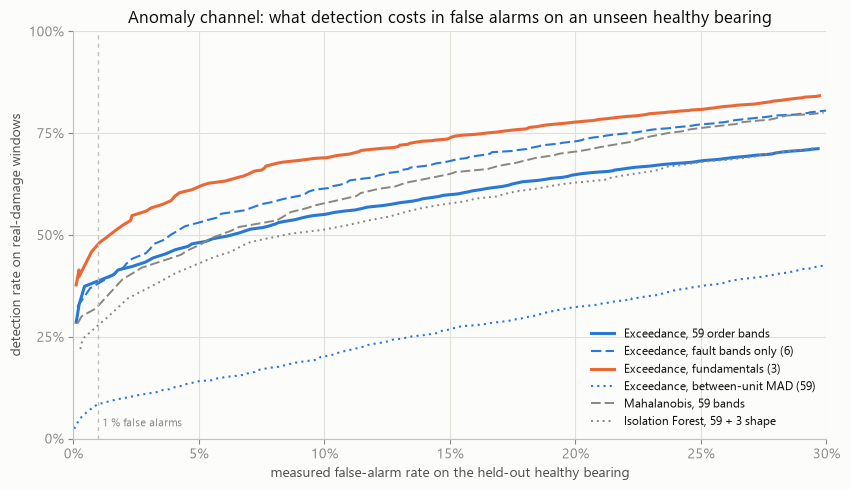

In [6]:
fig, ax = plt.subplots(figsize=(8.6, 5.0))
styles = {"Exceedance, 59 order bands": (C_BLUE, "-", 2.2),
          "Exceedance, fundamentals (3)": (C_ORANGE, "-", 2.2),
          "Exceedance, fault bands only (6)": (C_BLUE, (0, (5, 2)), 1.5),
          "Exceedance, between-unit MAD (59)": (C_BLUE, (0, (1, 2)), 1.5),
          "Mahalanobis, 59 bands": (MUTED, (0, (5, 2)), 1.4),
          "Isolation Forest, 59 + 3 shape": (MUTED, (0, (1, 2)), 1.4)}
for name, c in curves.items():
    col, ls, lw = styles[name]
    m = c["fpr"] <= 0.30
    ax.plot(c.loc[m, "fpr"], c.loc[m, "det_real"], color=col, ls=ls, lw=lw, label=name)
ax.axvline(0.01, color=BASE, lw=1, ls=(0, (3, 3)))
ax.text(0.0115, 0.03, "1 % false alarms", color=MUTED, fontsize=8)
ax.set_xlabel("measured false-alarm rate on the held-out healthy bearing")
ax.set_ylabel("detection rate on real-damage windows")
ax.set_xlim(0, 0.30)
ax.set_ylim(0, 1.0)
ax.set_xticks([0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30],
              ["0%", "5%", "10%", "15%", "20%", "25%", "30%"])
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0], ["0%", "25%", "50%", "75%", "100%"])
ax.set_title("Anomaly channel: what detection costs in false alarms on an unseen healthy bearing")
ax.legend(fontsize=8.5, loc="lower right")
plt.tight_layout()
plt.show()

## Reading the scorer comparison

- **The rich representation loses to the three fundamentals.** At a matched
  1 % false-alarm rate the 59-band exceedance detects 38.7 % of real-damage
  windows; the three physics-anchored fundamentals detect 47.8 %. Mahalanobis
  (32.7 %) and Isolation Forest (27.9 %) are worse still. Fifty-nine bands buy
  fifty-nine chances to trip on unit-to-unit variation, and max-pooling
  charges for every one of them. **This was the design hypothesis of the
  notebook and the data refuses it** — the same lesson as notebook 05's
  feature ablation, now in the unsupervised setting: physics narrows the
  search space, and narrowing is the win.
- **Restricting to fault bands does not help either** (38.1 %): the six
  k × BPFO/BPFI bands are 0.5 orders wide, wide enough to admit neighbouring
  rig lines. The fundamentals' ±4 Hz windows are tighter — precision in
  *where you look* beats coverage.
- **The between-unit ablation prices the problem.** Swap the noise model from
  within-unit window scatter to between-unit healthy scatter and detection
  collapses from 38.7 % to **8.5 %** at the same 1 % false-alarm rate. In
  other words, roughly four fifths of what the standard detector calls
  "anomalous" is inside the envelope of normal healthy-unit variation; it
  only looks detectable because pooled windows understate that spread.
- **Nothing here is a usable detector.** The best scorer reaches 69.0 % only
  once false alarms are allowed up to 10 %; at 1 % it sees under half of all
  real-damage windows.

## Which bearings does the anomaly channel actually see?

Per-bearing detection at the 1 % operating point, at window level and at
recording level (majority of the 15 windows in one 4-second record — the
aggregation a real monitor would do before raising a ticket).

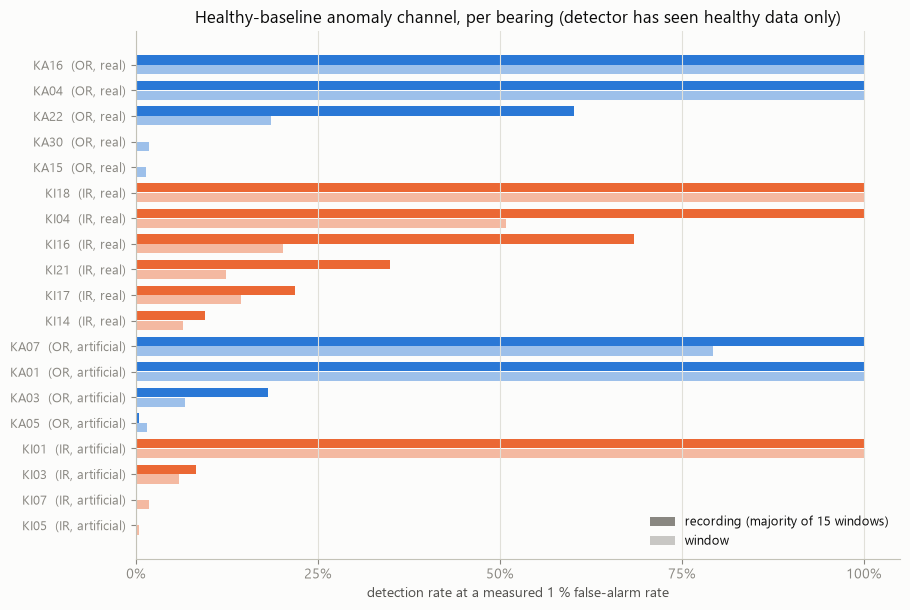

,window,recording,Condition,Domain
KI05,0.5%,0.0%,IR,artificial
KI07,1.8%,0.0%,IR,artificial
KI03,6.0%,8.3%,IR,artificial
KI01,100.0%,100.0%,IR,artificial
KA05,1.6%,0.5%,OR,artificial
KA03,6.8%,18.2%,OR,artificial
KA01,100.0%,100.0%,OR,artificial
KA07,79.3%,100.0%,OR,artificial
KI14,6.4%,9.5%,IR,real
KI17,14.4%,21.8%,IR,real


In [7]:
BEST = "Exceedance, 59 order bands"
win_c, rec_c = curves[BEST], sweep(BEST, recording=True)
per_bearing = pd.DataFrame({
    "window": at_fpr(win_c, 0.01, DAMAGED),
    "recording": at_fpr(rec_c, 0.01, DAMAGED)}).join(LABEL)
order = per_bearing.sort_values(["Domain", "Condition", "recording"]).index

fig, ax = plt.subplots(figsize=(9.2, 6.2))
y = np.arange(len(order))
s = per_bearing.loc[order]
colors = [CLASS_COLOR[c] for c in s["Condition"]]
ax.barh(y + 0.19, s["recording"], height=0.36, color=colors)
ax.barh(y - 0.19, s["window"], height=0.36, color=colors, alpha=0.45)
ax.set_yticks(y, [f"{c}  ({s.loc[c, 'Condition']}, {s.loc[c, 'Domain']})" for c in order], fontsize=9)
ax.set_xlim(0, 1.05)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0], ["0%", "25%", "50%", "75%", "100%"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("detection rate at a measured 1 % false-alarm rate")
ax.set_title("Healthy-baseline anomaly channel, per bearing (detector has seen healthy data only)")
# bar colour already encodes the fault class via the y labels; the legend only
# has to explain the light/dark pairing, so keep its swatches class-neutral
handles = [Patch(facecolor=MUTED, label="recording (majority of 15 windows)"),
           Patch(facecolor=MUTED, alpha=0.45, label="window")]
ax.legend(handles=handles, fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()
per_bearing.loc[order].style.format({"window": "{:.1%}", "recording": "{:.1%}"})

## Reading the per-bearing detection

- **Notebook 06's hypothesis is half right.** KA22 — the bearing the anomaly
  framing was invented for — goes from 18.5 % of windows to **60.2 % of
  recordings**, the largest aggregation gain in the set. Its off-frequency
  line is persistent enough to survive majority voting. The proposal was
  sound for the case it was designed for.
- **KA30 and KA15 are not rescued: 0.2 % and 0.0 % at recording level.**
  Aggregation makes them *worse*, which is the signature of a signal that is
  absent rather than noisy. The indentation verdict of notebook 06 now holds
  against an unsupervised detector with access to the whole envelope
  spectrum, not just ball-pass features — the strongest form of that claim
  the data can support.
- **Recording-level aggregation is a real lever for the marginal cases:**
  KI04 50.8 → 100 %, KI16 20.2 → 68.5 %, KI21 12.4 → 35.0 %, KA22
  18.5 → 60.2 %. Free sensitivity, at the cost of 4 seconds of latency —
  cheap in predictive maintenance. Any window-level number in notebooks 04–06
  understates what a deployed monitor achieves.
- **The artificial bearings split violently.** KA01 and KI01 (EDM) and KA07
  (drilled, OR) are caught in 100 % of recordings, while the four engraver
  bearings and the drilled IR bearing (KA03, KA05, KI03, KI05, KI07) sit at
  **0–18 %** — *less* anomalous than most real damage. Notebook 03's
  "artificial damage is more severe than real" was measured on the two EDM
  bearings and does not generalize to the eight-bearing set.

## Why KA15 and KA22 are invisible, in one table

The severity table below is the whole notebook in numbers: the median
envelope level of each bearing at the three fundamentals, with the healthy
population's own range shaded.

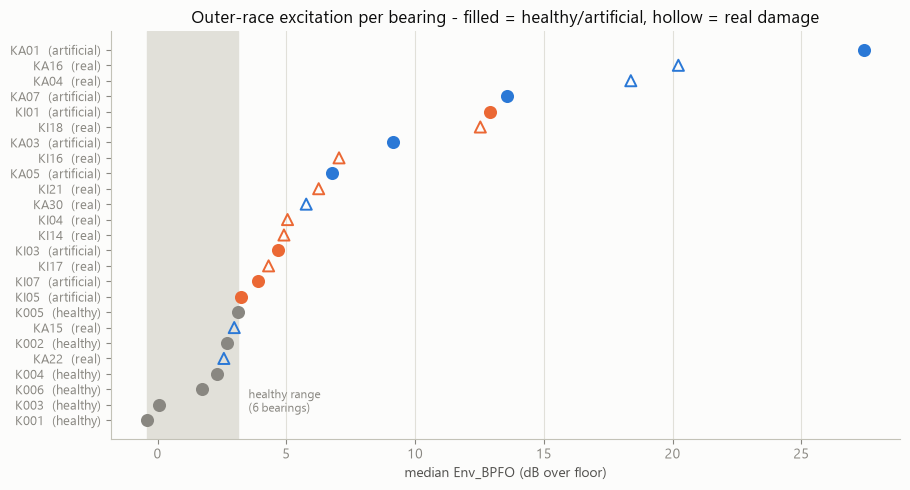

      Env_BPFO_dB  Env_BPFI_dB  Env_fr_dB Condition      Domain
Code                                                           
K001        -0.43        -0.89       0.29   Healthy     healthy
K003         0.05        -0.18       0.04   Healthy     healthy
K006         1.73        -0.37       1.90   Healthy     healthy
K004         2.30         2.38       3.60   Healthy     healthy
KA22         2.57         3.44       5.61        OR        real
K002         2.71         0.61       4.30   Healthy     healthy
KA15         2.98         2.81       4.62        OR        real
K005         3.13         3.01       3.36   Healthy     healthy
KI05         3.22         3.60       4.71        IR  artificial
KI07         3.89         5.85       7.26        IR  artificial
KI17         4.31         1.54       7.09        IR        real
KI03         4.66         6.32       8.18        IR  artificial
KI14         4.91         6.23       7.34        IR        real
KI04         5.05         9.57      13.2

In [8]:
sev = ds.groupby("Code")[FUND].median().join(LABEL)
hi, lo = sev.loc[HEALTHY, "Env_BPFO_dB"].max(), sev.loc[HEALTHY, "Env_BPFO_dB"].min()
sev = sev.sort_values("Env_BPFO_dB")

fig, ax = plt.subplots(figsize=(9.2, 5.0))
ax.axvspan(lo, hi, color=GRID, zorder=0)
ax.text(hi + 0.4, 0.3, "healthy range\n(6 bearings)", color=MUTED, fontsize=8.5, va="bottom")
y = np.arange(len(sev))
for i, (code, row) in enumerate(sev.iterrows()):
    marker = "o" if row["Domain"] != "real" else "^"
    ax.scatter(row["Env_BPFO_dB"], i, s=64, marker=marker, zorder=3,
               facecolors=CLASS_COLOR[row["Condition"]] if row["Domain"] != "real" else "none",
               edgecolors=CLASS_COLOR[row["Condition"]], linewidths=1.4)
ax.set_yticks(y, [f"{c}  ({sev.loc[c, 'Domain']})" for c in sev.index], fontsize=9)
ax.grid(axis="y", visible=False)
ax.set_xlabel("median Env_BPFO (dB over floor)")
ax.set_title("Outer-race excitation per bearing - filled = healthy/artificial, hollow = real damage")
plt.tight_layout()
plt.show()
print(sev.round(2).to_string())

## Reading the severity table

- **The two invisible outer-race bearings are interleaved with the healthy
  ones.** Sorted by outer-race excitation the sequence runs K004 (2.30 dB),
  **KA22 (2.57)**, K002 (2.71), **KA15 (2.98)**, K005 (3.13). They are not
  weak signals to be teased out with a better threshold — they are *inside*
  the healthy population. No decision rule on outer-race excitation can
  separate them from healthy without also condemning K002, K004 and K005.
- That is the same fact the classifier reports as 6.7 % accuracy (notebook
  05) and the anomaly channel reports as 1.5 % detection — two methods, one
  physical cause, and the cause is *not* in the model.
- **The healthy bearings are not at zero either**: −0.43 dB (K001) to
  3.13 dB (K005), a **3.6 dB span** that exceeds the gap between healthy and
  three of the eleven real-damage bearings. Notebook 05's "unit-to-unit
  variability is comparable to the class signal" is here in its sharpest
  form.
- Read the other way, the table also explains the successes: KA01 (27.4 dB),
  KA16 (20.2), KA04 (18.4), KA07 (13.6), KI01 (12.9) and KI18 (12.5) are
  10–25 dB clear of everything healthy. Those are the bearings every method
  in notebooks 04–07 gets right.

## Where the alarm fires: detectable ≠ attributable, quantified

The exceedance score is interpretable by construction — the band that
produced the maximum z is *where* the detector saw something. Tabulating that
band per bearing turns notebook 06's qualitative KA22 argument into a
benchmark-wide statement about what an explanation layer is entitled to say.

In [9]:
NAMED = {1.0: "fr", 2.0: "2 x fr", 3.0: "BPFO", 5.0: "BPFI", 6.0: "2 x BPFO",
         9.0: "3 x BPFO", 10.0: "2 x BPFI", 15.0: "3 x BPFI"}
rows = []
for c in DAMAGED:
    counts = np.zeros(len(BANDS))
    for held in HEALTHY:
        Z = folds[BEST][held]["model"].z(X_of[c])
        counts += np.bincount(Z.argmax(axis=1), minlength=len(BANDS))
    top, second = counts.argsort()[::-1][:2]
    rows.append({"Code": c, "top order": ORDER_CENTERS[top],
                 "share of windows": counts[top] / counts.sum(),
                 "interpretation": NAMED.get(ORDER_CENTERS[top], "-- no fault frequency --"),
                 "2nd order": ORDER_CENTERS[second]})
attr = pd.DataFrame(rows).set_index("Code").join(LABEL)
attr = attr.loc[per_bearing.sort_values(["Domain", "Condition"]).index]
attr["detected (rec.)"] = per_bearing["recording"]
named = attr["interpretation"].isin(["BPFO", "BPFI", "2 x BPFO", "3 x BPFO", "2 x BPFI", "3 x BPFI"])
print(attr.to_string(formatters={"share of windows": "{:.0%}".format,
                                 "detected (rec.)": "{:.0%}".format}))
print(f"\nfires in a ball-pass band: {named.sum()}/{len(attr)} bearings; "
      f"at shaft rate: {(attr['interpretation'].isin(['fr', '2 x fr'])).sum()}; "
      f"at no named frequency: {(attr['interpretation'] == '-- no fault frequency --').sum()}")

      top order share of windows            interpretation  2nd order Condition      Domain detected (rec.)
KI01        1.0              98%                        fr        9.0        IR  artificial            100%
KI03        1.0              26%                        fr        5.0        IR  artificial              8%
KI05        5.5              13%  -- no fault frequency --       19.0        IR  artificial              0%
KI07        5.0              24%                      BPFI        1.0        IR  artificial              0%
KA01        9.0             100%                  3 x BPFO       29.5        OR  artificial            100%
KA03        3.0              49%                      BPFO        7.5        OR  artificial             18%
KA05        3.0              23%                      BPFO        9.0        OR  artificial              1%
KA07        3.0              56%                      BPFO        9.0        OR  artificial            100%
KI04        1.0             

## Reading the attribution table

- **KA22's alarm lands at order 5.5, not at BPFO (3.07) or BPFI (4.93)**, with
  order 11.5 second — the ≈ 2× harmonic of the same line. An unsupervised
  detector that was never told the fault frequencies independently
  rediscovers notebook 06's 144.5 Hz ≈ 5.75 × fr component. Two methods, one
  answer, and the answer is *not a bearing frequency*. KI05 is the second
  bearing to fire there, so the band is not a KA22 idiosyncrasy.
- **Only twelve of nineteen damaged bearings fire in a ball-pass band at
  all.** Five of them (KI01, KI03, KI04, KI16, KI21) fire loudest at **shaft
  rate** — a frequency that indicates unbalance, misalignment or looseness in
  textbook diagnostics, and here mostly reflects fault-induced load
  modulation. A monitor is right to alarm; an explanation layer that renders
  that alarm as "inner-race defect detected" is inventing the causal half.
- The bearings that *do* fire at their own fault frequency fire there
  overwhelmingly (KA04 98 %, KA16 94 %, KI18 78 % of windows), while the
  marginal ones scatter (KA30 20 %, KA15 10 %). Concentration of the firing
  band is itself a usable confidence signal for the explanation layer.
- **This is the concrete requirement the RAG/LLM layer inherits:** the
  numeric channel must hand the language layer *the band it fired in*, and
  the language layer must be able to say **"anomalous energy at 5.5 × shaft
  rate, not matching any bearing fault frequency"** — an honest,
  non-attributing explanation. Paper 4's closed-book LLM writing fault
  narratives from memory could not have produced that sentence; it is
  exactly the failure mode our groundedness evaluation has to catch.

## The two-channel system, and the number nobody measured

Finally, the question notebook 06 actually asked: does adding this channel to
the fault classifier make the system safer? Both channels are trained without
the held-out healthy bearing (the classifier on the remaining 5 healthy +
8 artificial bearings, the anomaly baseline on the same 5 healthy), and the
system alarms if **either** fires. Two numbers, swept together:

- **missed-fault rate** — real-damage windows that neither channel flags;
- **false-alarm rate** — windows of an unseen *healthy* bearing that either
  channel flags.

Notebooks 04–06 never computed the second one.

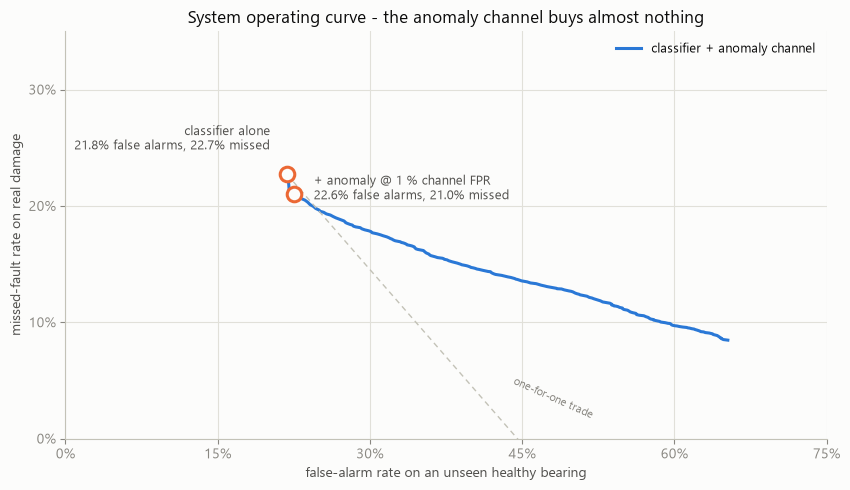

classifier alone                : 21.8% false alarms, 22.7% missed   [KA22 54.6% missed]
+ anomaly @ 1 % channel FPR     : 22.6% false alarms, 21.0% missed   [KA22 43.7% missed]
+ anomaly pushed to 30 % FA     : 29.9% false alarms, 17.9% missed   [KA22 28.1% missed]

per-healthy-bearing false alarms, classifier alone:
   K001 3.3%,  K002 32.7%,  K003 5.0%,  K004 37.3%,  K005 38.7%,  K006 14.0%
per-real-bearing missed fault, classifier alone:
   KA04 0.0%,  KA15 62.9%,  KA16 0.0%,  KA22 54.6%,  KA30 45.9%,  KI04 0.9%,  KI14 22.1%,  KI16 9.7%,  KI17 45.1%,  KI18 0.0%,  KI21 8.7%


In [10]:
clf_alarm, clf_correct = {}, {}
for held in HEALTHY:
    tr_rf = ds[((ds["Domain"] == "healthy") & (ds["Code"] != held)) | (ds["Domain"] == "artificial")]
    rf = RandomForestClassifier(**RF_KW).fit(tr_rf[FUND], tr_rf["Condition"])
    for c in [held] + REAL:
        pred = rf.predict(ds.loc[ds["Code"] == c, FUND])
        clf_alarm[(held, c)] = pred != "Healthy"
        clf_correct[(held, c)] = pred == LABEL.loc[c, "Condition"]

rows = []
for q in np.concatenate([QS, [1.1]]):          # q = 1.1 -> anomaly channel switched off
    fa, missed = [], {c: [] for c in REAL}
    for held in HEALTHY:
        e = folds[BEST][held]
        thr = np.inf if q > 1 else np.quantile(e["train"], q)
        fa.append((clf_alarm[(held, held)] | (e["per_code"][held] > thr)).mean())
        for c in REAL:
            missed[c].append(1 - (clf_alarm[(held, c)] | (e["per_code"][c] > thr)).mean())
    rows.append(dict(q=q, false_alarm=np.mean(fa),
                     missed=np.mean([np.mean(v) for v in missed.values()]),
                     **{c: np.mean(v) for c, v in missed.items()}))
system = pd.DataFrame(rows)
clf_only = system.iloc[-1]

q_1pct = float(np.interp(0.01, curves[BEST]["fpr"], curves[BEST]["q"]))
at_1pct = system.iloc[(system["q"] - q_1pct).abs().argmin()]
at_30 = system.iloc[(system["false_alarm"] - 0.30).abs().argmin()]

fig, ax = plt.subplots(figsize=(8.6, 5.0))
m = system["q"] <= 1
ax.plot(system.loc[m, "false_alarm"], system.loc[m, "missed"], color=C_BLUE, lw=2.2,
        label="classifier + anomaly channel")
# slope -1 reference through the classifier-alone point: one point of extra false
# alarm bought for exactly one point of missed fault.
fa0, ms0 = clf_only["false_alarm"], clf_only["missed"]
xs = np.array([fa0, 0.75])
ax.plot(xs, ms0 - (xs - fa0), color=BASE, lw=1, ls=(0, (4, 3)))
ax.text(0.44, ms0 - (0.44 - fa0) + 0.012, "one-for-one trade", color=MUTED, fontsize=8, rotation=-24)
for pt, lab, dx, dy in ((clf_only, "classifier alone", -12, 18),
                        (at_1pct, "+ anomaly @ 1 % channel FPR", 14, -4)):
    ax.scatter([pt["false_alarm"]], [pt["missed"]], s=110, zorder=4,
               facecolors=SURFACE, edgecolors=C_ORANGE, linewidths=2.2)
    ax.annotate(f"{lab}\n{pt['false_alarm']:.1%} false alarms, {pt['missed']:.1%} missed",
                (pt["false_alarm"], pt["missed"]), textcoords="offset points",
                xytext=(dx, dy), ha="right" if dx < 0 else "left", fontsize=9, color=INK2)
ax.set_xlim(0, 0.75)
ax.set_ylim(0, 0.35)
ax.set_xticks([0, 0.15, 0.30, 0.45, 0.60, 0.75], ["0%", "15%", "30%", "45%", "60%", "75%"])
ax.set_yticks([0, 0.1, 0.2, 0.3], ["0%", "10%", "20%", "30%"])
ax.set_xlabel("false-alarm rate on an unseen healthy bearing")
ax.set_ylabel("missed-fault rate on real damage")
ax.set_title("System operating curve - the anomaly channel buys almost nothing")
ax.legend(fontsize=9, loc="upper right")
plt.tight_layout()
plt.show()

for lab, r in (("classifier alone                ", clf_only),
               ("+ anomaly @ 1 % channel FPR     ", at_1pct),
               ("+ anomaly pushed to 30 % FA     ", at_30)):
    print(f"{lab}: {r['false_alarm']:5.1%} false alarms, {r['missed']:5.1%} missed"
          f"   [KA22 {r['KA22']:.1%} missed]")
print("\nper-healthy-bearing false alarms, classifier alone:")
print("   " + ",  ".join(f"{h} {np.mean(clf_alarm[(h, h)]):.1%}" for h in HEALTHY))
print("per-real-bearing missed fault, classifier alone:")
print("   " + ",  ".join(f"{c} {clf_only[c]:.1%}" for c in REAL))

## Reading the system curve

- **The anomaly channel is not the fix.** Added at its own 1 % operating
  point it moves missed faults from 22.7 % to **21.0 %** and false alarms
  from 21.8 % to **22.6 %** — 0.8 points paid for 1.7 points gained, worth
  taking but tiny. Then it saturates: pushing the channel until the system
  false-alarms on 30 % of healthy windows buys only another 3.1 points
  (17.9 % missed), which is **worse than the one-for-one diagonal** drawn
  through the classifier's operating point. The one place it genuinely helps
  is the bearing it was designed for: KA22's missed rate falls
  54.6 % → 43.7 % at window level, and its recordings are caught 60 % of the
  time.
- **The real finding is the axis nobody had plotted.** The fault classifier
  false-alarms on **21.8 % of windows from healthy bearings it has never
  seen** — K005 38.7 %, K004 37.3 %, K002 32.7 %, against 3.3 % for K001.
  Notebooks 04–06 scored only faulty bearings and never saw this. A
  maintenance system that condemns a third of a new healthy motor's windows
  is unusable long before its missed-fault rate matters, and the false alarms
  concentrate on exactly the healthy bearings whose installation signature
  differs from the training majority.
- **Both failure directions have the same cause.** Unit-to-unit variation
  puts K004/K005 above the fault threshold and KA15/KA22 below it. This is
  not a classifier problem, an anomaly-detector problem, or a
  feature-engineering problem — it is a **calibration** problem, and the only
  lever the data supports is a per-unit healthy reference (notebook 05,
  finding 4).
- For RQ4 this closes a loop: the artificial→real "domain gap" is dominated
  by unit-to-unit variation that is present *within* the healthy population
  itself, before any damage or any simulator is involved.

## Findings (executed 2026-08-17)

1. **The healthy population is two populations.** Six nominally identical
   healthy bearings split into K001/K003/K006 and K004/K005 (K002 between),
   **2.7–3.8 dB apart** across 59 envelope order bands — driven by the
   ≈ 52.7 Hz rig harmonic family (≈ 20 dB vs 8–12 dB), i.e. an *installation*
   signature, not a bearing one. The split does not follow the documented
   run-in history (Lessmeier Table 7): K001 (> 50 h) and K003 (1 h) are the
   two most similar bearings in the set.
2. **A single-unit healthy baseline can be 100 % wrong on another healthy
   unit.** Calibrated to 1 % false alarms on itself, the K004 baseline flags
   *every* window of K001, K003 and K006 (driven by order ≈ 28, not a bearing
   band), while baselines from the other group stay under 11 %. Pooling five
   healthy bearings is what makes the detector usable — and pooling is only
   possible because this is a benchmark, not a plant.
3. **The richer representation loses to physics — again.** At a matched 1 %
   false-alarm rate on an unseen healthy bearing, real-damage detection is
   47.8 % for the three envelope fundamentals, 38.7 % for 59 order bands,
   38.1 % for fault bands only, 32.7 % Mahalanobis, 27.9 % Isolation Forest.
   The notebook's own design hypothesis (more bands, more coverage) is
   refuted.
4. **Four fifths of the "anomaly" is healthy unit-to-unit variation.**
   Re-estimating the detector's noise model from between-unit healthy scatter
   instead of within-unit window scatter drops detection from 38.7 % to
   **8.5 %** at the same false-alarm rate.
5. **Notebook 06's proposal is confirmed narrowly and refuted broadly.**
   KA22 — the case it was designed for — is caught in **60.2 % of
   recordings** by an unsupervised detector, and its alarm fires at order
   **5.5**, independently rediscovering the 144.5 Hz component. But KA15 and
   KA30 stay at 0.0 % / 0.2 % at recording level (aggregation makes them
   *worse*, the signature of an absent signal), and as a system add-on the
   channel moves missed faults 22.7 % → 21.0 % for 0.8 points of extra false
   alarm and then saturates — pushed to a 30 % false-alarm rate it recovers
   only 3.1 further points.
6. **KA22 and KA15 are interleaved with the healthy bearings at BPFO** —
   K004 2.30 dB, KA22 2.57, K002 2.71, KA15 2.98, K005 3.13. Their
   invisibility is a property of the physics and the healthy spread, not of
   any model.
7. **The unmeasured number: 21.8 % false alarms on unseen healthy
   bearings** (K005 38.7 %, K004 37.3 %, K002 32.7 %, K001 3.3 %) — from the
   same classifier notebooks 05/06 report as 60.6 % accurate. Every previous
   notebook scored faulty bearings only. Missed-fault and false-alarm rates
   have a single shared cause: unit-to-unit variability, in both directions.
8. **Recording-level aggregation is a free lever** (KI04 50.8 → 100 %,
   KI16 20.2 → 68.5 %, KA22 18.5 → 60.2 %) that costs 4 seconds of latency.
   Window-level numbers in notebooks 04–06 understate deployed performance
   for the marginal bearings — though not for the physically silent ones.
9. **"Artificial damage is more severe than real" is an EDM-only artifact.**
   KA01/KI01 (EDM) and KA07 (drilled OR) are caught in 100 % of recordings;
   the four engraver bearings and the drilled IR bearing sit at **0–18 %**,
   *below* most real damage. Notebook 03's severity claim was measured on the
   two EDM bearings and does not generalize to the eight-bearing set.
10. **Caveats:** one operating condition (N15_M07_F10); one bearing type on one
    rig, so "installation signature" is inferred from the split's structure,
    not from independent re-mounting experiments; the between-unit MAD is
    estimated from five bearing medians; single classifier family (RF).